# Bước 3-5: Trích chọn đặc trưng, Huấn luyện mô hình, Đánh giá
## Bài toán: Phát hiện Spam / Ham cho bình luận Facebook PTIT

Notebook này đọc dữ liệu đã gán nhãn từ file CSV với các cột:
`id, label, cleaned_text, text, comment_type, reaction_count`

- `label`: nhãn đã gán, nhận giá trị `"spam"` hoặc `"ham"`.
- `cleaned_text`: văn bản đã qua bước tiền xử lý/làm sạch.
- `comment_type`, `reaction_count`: thông tin phụ, dùng cho phần mở rộng (bonus) ở cuối notebook.

Các bước thực hiện:
- **Bước 3 — Trích chọn đặc trưng**: Bag-of-Words (BoW), TF-IDF, Word Embeddings (Word2Vec).
- **Bước 4 — Xây dựng và huấn luyện mô hình**: Naive Bayes, SVM, trên từng loại đặc trưng.
- **Bước 5 — Đánh giá mô hình**: Accuracy, Precision, Recall, F1-Score, Confusion Matrix, và **biểu đồ so sánh**.


## 0. Cài đặt thư viện cần thiết

In [1]:
!pip install gensim underthesea scikit-learn pandas matplotlib huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 69.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 13.5 MB/s eta 0:00:00


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack, csr_matrix

from underthesea import word_tokenize
from gensim.models import Word2Vec

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.svm import LinearSVC
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
POS_LABEL = "spam"   # nhãn được coi là lớp "dương" khi tính precision/recall/f1 nhị phân

## 1. Tải dataset từ Hugging Face Hub (gated) bằng Kaggle Secrets

Dataset được lưu dưới dạng **gated dataset** trên Hugging Face Hub, nên cần `HF_TOKEN`
có quyền truy cập (đã được chủ dataset phê duyệt) để tải về.

**Thiết lập secret trên Kaggle (làm 1 lần):**
1. Vào notebook Kaggle → menu **Add-ons → Secrets**.
2. Thêm secret mới với tên chính xác là `HF_TOKEN`, giá trị là Access Token của bạn
   (lấy tại huggingface.co/settings/tokens, chỉ cần quyền `read`).
3. Bật secret này cho notebook hiện tại (toggle "Attached").

> Lưu ý: tài khoản Hugging Face dùng token này phải đã được **phê duyệt truy cập**
> (approved) vào dataset gated tương ứng, nếu không `hf_hub_download` sẽ báo lỗi 403.

In [3]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import hf_hub_download

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")

HF_REPO_ID = "p-storm/ptit-facebook-comments-spamham" 
HF_FILENAME = "comments_labeled_export.csv"                   

csv_path = hf_hub_download(repo_id=HF_REPO_ID, filename=HF_FILENAME, repo_type="dataset", token=HF_TOKEN,)
print("Đã tải dataset về:", csv_path)

comments_labeled_export.csv: 0.00B [00:00, ?B/s]

Đã tải dataset về: /root/.cache/huggingface/hub/datasets--p-storm--ptit-facebook-comments-spamham/snapshots/912921ddf8709a661e1f2669dad298d365624457/comments_labeled_export.csv


## 1.1. Đọc dữ liệu đã gán nhãn

In [4]:
df = pd.read_csv(csv_path)

df = df[df["label"].isin(["spam", "ham"])].copy()
df = df.dropna(subset=["cleaned_text"]).reset_index(drop=True)
df["cleaned_text"] = df["cleaned_text"].astype(str)

print(f"Tổng số bình luận: {len(df)}")
print(df["label"].value_counts())
print()
print("Phân bố comment_type:")
print(df["comment_type"].value_counts() if "comment_type" in df.columns else "Không có cột comment_type")
df.head()

Tổng số bình luận: 31931
label
ham     28722
spam     3209
Name: count, dtype: int64

Phân bố comment_type:
comment_type
comment    19952
reply      11979
Name: count, dtype: int64


,id,label,cleaned_text,text,comment_type,reaction_count
0,cmt_0,ham,Cải thiện nhận bằng có chậm không b nhỉ,Cải thiện nhận bằng có chậm không b nhỉ,comment,0
1,cmt_1,ham,Người tham gia ẩn danh 124 k liên quan. Miễn t...,Người tham gia ẩn danh 124 k liên quan. Miễn t...,reply,0
2,cmt_2,ham,"Người tham gia ẩn danh 124 ko b ơi, D22 kỳ đôn...","Người tham gia ẩn danh 124 ko b ơi, D22 kỳ đôn...",reply,0
3,cmt_3,ham,Ké môn Phát triển ứng dụng thiết bị di động ạ,Ké môn Phát triển ứng dụng thiết bị di động ạ,comment,0
4,cmt_4,ham,.,.,comment,0


## 2. Tiền xử lý & tách từ tiếng Việt

Dữ liệu trong `cleaned_text` đã được làm sạch (xóa HTML, chuẩn hóa dấu câu...) ở bước trước,
ở đây ta chỉ cần **tách từ** (word segmentation) bằng `underthesea` để phục vụ BoW/TF-IDF/Word2Vec.

In [5]:
def tokenize_vi(text):
    return word_tokenize(str(text), format="text")

df["text_tokenized"] = df["cleaned_text"].apply(tokenize_vi)
df[["cleaned_text", "text_tokenized"]].head()

,cleaned_text,text_tokenized
0,Cải thiện nhận bằng có chậm không b nhỉ,Cải_thiện nhận bằng có chậm không b nhỉ
1,Người tham gia ẩn danh 124 k liên quan. Miễn t...,Người tham_gia ẩn_danh 124 k liên_quan . Miễn ...
2,"Người tham gia ẩn danh 124 ko b ơi, D22 kỳ đôn...","Người tham_gia ẩn_danh 124 ko b ơi , D22_kỳ đô..."
3,Ké môn Phát triển ứng dụng thiết bị di động ạ,Ké_môn Phát_triển ứng_dụng thiết_bị di_động ạ
4,.,.


## 3. Chia tập huấn luyện / kiểm tra (train / test)

In [6]:
X = df["text_tokenized"].values
y = df["label"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f"Tập huấn luyện: {len(X_train)} mẫu  |  spam: {(y_train=='spam').sum()}  ham: {(y_train=='ham').sum()}")
print(f"Tập kiểm tra:   {len(X_test)} mẫu  |  spam: {(y_test=='spam').sum()}  ham: {(y_test=='ham').sum()}")

Tập huấn luyện: 25544 mẫu  |  spam: 2567  ham: 22977
Tập kiểm tra:   6387 mẫu  |  spam: 642  ham: 5745


---
# Bước 3: Trích chọn đặc trưng

Thử nghiệm 3 phương pháp: **BoW**, **TF-IDF**, và **Word Embeddings (Word2Vec)**.

### 3.1. Bag-of-Words (BoW)

In [7]:
bow_vectorizer = CountVectorizer(max_features=5000)
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)
print("Kích thước ma trận BoW (train):", X_train_bow.shape)

Kích thước ma trận BoW (train): (25544, 5000)


### 3.2. TF-IDF

In [8]:
tfidf_vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)
print("Kích thước ma trận TF-IDF (train):", X_train_tfidf.shape)

Kích thước ma trận TF-IDF (train): (25544, 5000)


### 3.3. Word Embeddings (Word2Vec)

Huấn luyện Word2Vec trên chính tập huấn luyện, biểu diễn mỗi bình luận bằng
**vector trung bình cộng** của các từ trong câu.

In [9]:
tokenized_sentences = [sent.split() for sent in X_train]

w2v_model = Word2Vec(
    sentences=tokenized_sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    seed=RANDOM_STATE,
)

def sentence_to_vec(sentence, model, vector_size):
    words = sentence.split()
    vectors = [model.wv[w] for w in words if w in model.wv]
    if len(vectors) == 0:
        return np.zeros(vector_size)
    return np.mean(vectors, axis=0)

X_train_w2v = np.array([sentence_to_vec(s, w2v_model, 100) for s in X_train])
X_test_w2v = np.array([sentence_to_vec(s, w2v_model, 100) for s in X_test])
print("Kích thước ma trận Word2Vec (train):", X_train_w2v.shape)

Kích thước ma trận Word2Vec (train): (25544, 100)


---
# Bước 4: Xây dựng và huấn luyện mô hình

Áp dụng **Naive Bayes** và **SVM** cho từng loại đặc trưng.

> `MultinomialNB` cho BoW/TF-IDF (giá trị không âm); `GaussianNB` cho Word2Vec (có giá trị âm).

In [10]:
feature_sets = {
    "BoW": (X_train_bow, X_test_bow),
    "TF-IDF": (X_train_tfidf, X_test_tfidf),
    "Word2Vec": (X_train_w2v, X_test_w2v),
}

results = []
predictions = {}

for feat_name, (Xtr, Xte) in feature_sets.items():
    nb_model = GaussianNB() if feat_name == "Word2Vec" else MultinomialNB()
    nb_model.fit(Xtr, y_train)
    nb_pred = nb_model.predict(Xte)

    svm_model = LinearSVC(random_state=RANDOM_STATE, max_iter=5000)
    svm_model.fit(Xtr, y_train)
    svm_pred = svm_model.predict(Xte)

    for algo_name, y_pred in [("Naive Bayes", nb_pred), ("SVM", svm_pred)]:
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, pos_label=POS_LABEL, zero_division=0)
        rec = recall_score(y_test, y_pred, pos_label=POS_LABEL, zero_division=0)
        f1 = f1_score(y_test, y_pred, pos_label=POS_LABEL, zero_division=0)

        results.append({
            "Đặc trưng": feat_name,
            "Thuật toán": algo_name,
            "Accuracy": acc,
            f"Precision ({POS_LABEL})": prec,
            f"Recall ({POS_LABEL})": rec,
            f"F1-Score ({POS_LABEL})": f1,
        })
        predictions[f"{feat_name} + {algo_name}"] = y_pred

results_df = pd.DataFrame(results)
results_df

,Đặc trưng,Thuật toán,Accuracy,Precision (spam),Recall (spam),F1-Score (spam)
0,BoW,Naive Bayes,0.922342,0.666667,0.454829,0.540741
1,BoW,SVM,0.928605,0.770349,0.412773,0.537525
2,TF-IDF,Naive Bayes,0.924847,0.875000,0.294393,0.440559
3,TF-IDF,SVM,0.930640,0.809969,0.404984,0.539979
4,Word2Vec,Naive Bayes,0.797401,0.247287,0.496885,0.330228
5,Word2Vec,SVM,0.927822,0.860558,0.336449,0.483763


---
# Bước 5: Đánh giá mô hình

## 5.1. Bảng chỉ số chi tiết theo từng lớp (classification report)

In [11]:
for name, y_pred in predictions.items():
    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, zero_division=0))
    print()

===== BoW + Naive Bayes =====
              precision    recall  f1-score   support

         ham       0.94      0.97      0.96      5745
        spam       0.67      0.45      0.54       642

    accuracy                           0.92      6387
   macro avg       0.80      0.71      0.75      6387
weighted avg       0.91      0.92      0.92      6387


===== BoW + SVM =====
              precision    recall  f1-score   support

         ham       0.94      0.99      0.96      5745
        spam       0.77      0.41      0.54       642

    accuracy                           0.93      6387
   macro avg       0.85      0.70      0.75      6387
weighted avg       0.92      0.93      0.92      6387


===== TF-IDF + Naive Bayes =====
              precision    recall  f1-score   support

         ham       0.93      1.00      0.96      5745
        spam       0.88      0.29      0.44       642

    accuracy                           0.92      6387
   macro avg       0.90      0.64      0.

## 5.2. Confusion Matrix cho từng cặp (đặc trưng + thuật toán)

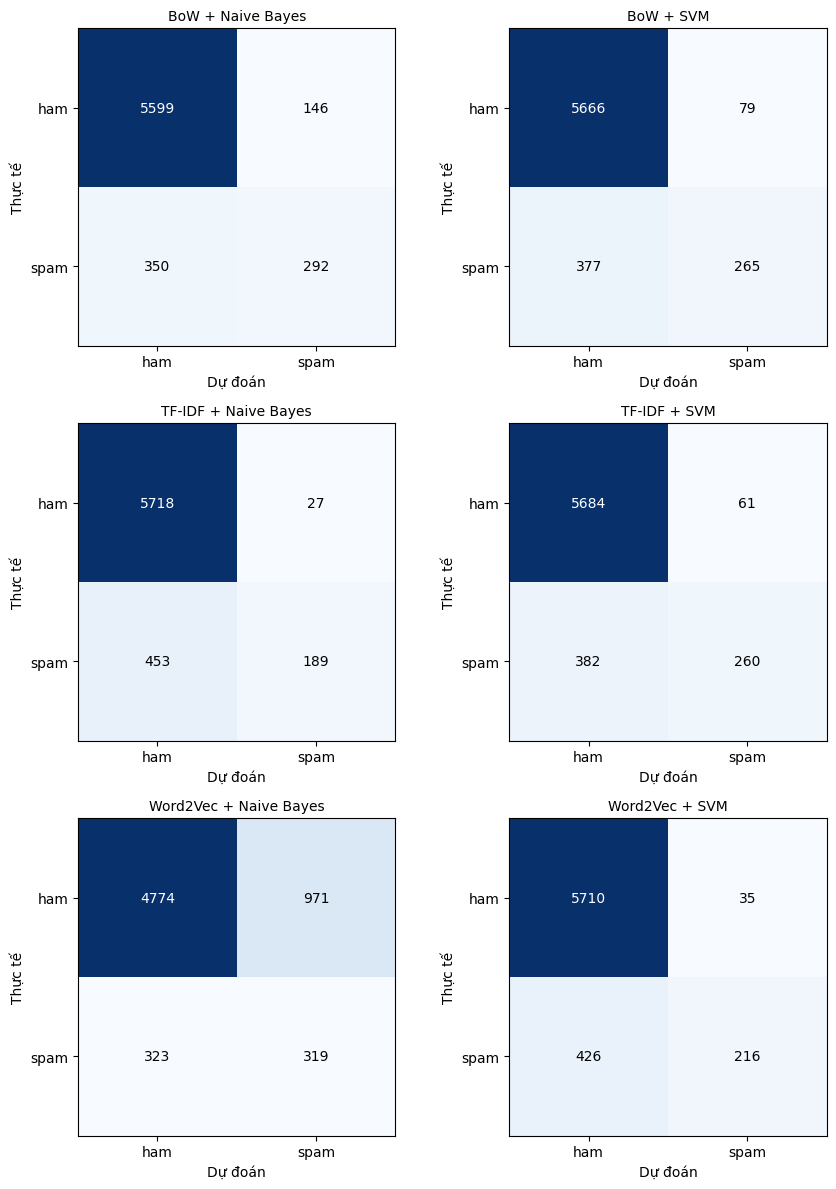

In [12]:
labels_order = ["ham", "spam"]
n_combos = len(predictions)
n_cols = 2
n_rows = int(np.ceil(n_combos / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(9, 4 * n_rows))
axes = axes.flatten()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=labels_order)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name, fontsize=10)
    ax.set_xticks(range(len(labels_order)))
    ax.set_yticks(range(len(labels_order)))
    ax.set_xticklabels(labels_order)
    ax.set_yticklabels(labels_order)
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")
    for i in range(len(labels_order)):
        for j in range(len(labels_order)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")

for k in range(len(predictions), len(axes)):
    axes[k].axis("off")

plt.tight_layout()
plt.show()

## 5.3. Biểu đồ so sánh hiệu suất giữa các phương pháp trích chọn đặc trưng và thuật toán

Biểu đồ cột nhóm so sánh **Accuracy** và **F1-Score (lớp spam)** giữa 6 tổ hợp
(3 phương pháp đặc trưng × 2 thuật toán).

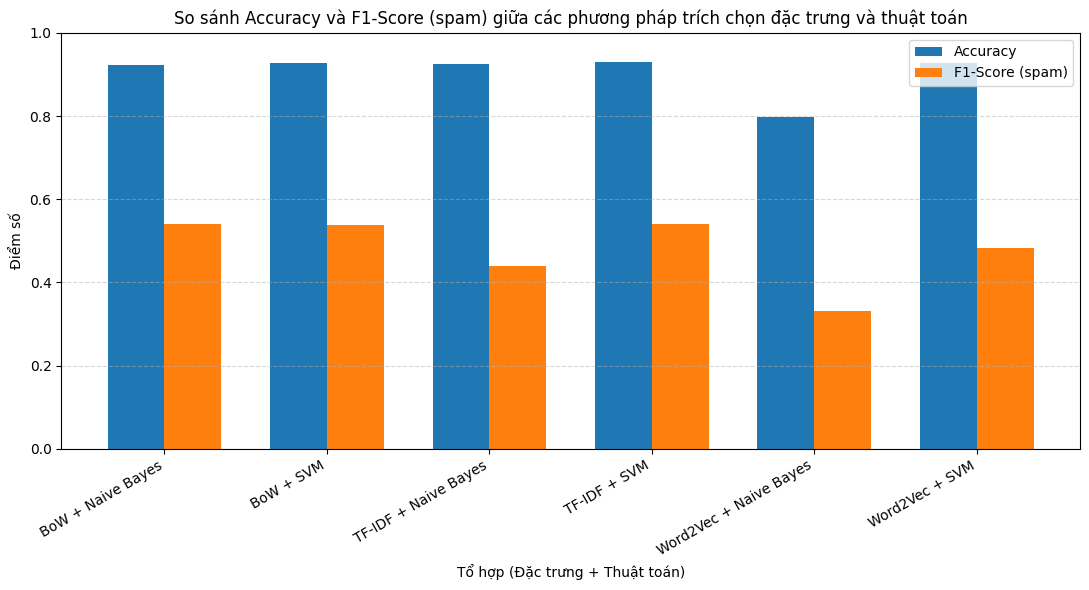

In [13]:
f1_col = "F1-Score (spam)"
results_df["Tổ hợp"] = results_df["Đặc trưng"] + " + " + results_df["Thuật toán"]

x = np.arange(len(results_df))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(x - width/2, results_df["Accuracy"], width, label="Accuracy")
ax.bar(x + width/2, results_df[f1_col], width, label=f1_col)

ax.set_xlabel("Tổ hợp (Đặc trưng + Thuật toán)")
ax.set_ylabel("Điểm số")
ax.set_title("So sánh Accuracy và F1-Score (spam) giữa các phương pháp trích chọn đặc trưng và thuật toán")
ax.set_xticks(x)
ax.set_xticklabels(results_df["Tổ hợp"], rotation=30, ha="right")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---
# (Mở rộng - không bắt buộc) Kết hợp thêm `comment_type` và `reaction_count`

Đây là phần thử nghiệm thêm: kết hợp đặc trưng văn bản (TF-IDF) với 2 đặc trưng phụ sẵn có
trong dữ liệu — `comment_type` (one-hot) và `reaction_count` (chuẩn hóa) — để xem có cải
thiện hiệu suất so với chỉ dùng văn bản hay không.

In [14]:
if "comment_type" in df.columns and "reaction_count" in df.columns:
    # One-hot encode comment_type
    ohe = OneHotEncoder(handle_unknown="ignore")
    train_type = ohe.fit_transform(df.loc[train_idx, ["comment_type"]].fillna("unknown"))
    test_type = ohe.transform(df.loc[test_idx, ["comment_type"]].fillna("unknown"))

    # Chuẩn hóa reaction_count
    scaler = StandardScaler()
    train_reaction = scaler.fit_transform(df.loc[train_idx, ["reaction_count"]].fillna(0))
    test_reaction = scaler.transform(df.loc[test_idx, ["reaction_count"]].fillna(0))

    # Ghép TF-IDF + comment_type (one-hot) + reaction_count (scaled)
    X_train_combined = hstack([X_train_tfidf, train_type, csr_matrix(train_reaction)])
    X_test_combined = hstack([X_test_tfidf, test_type, csr_matrix(test_reaction)])

    svm_combined = LinearSVC(random_state=RANDOM_STATE, max_iter=5000)
    svm_combined.fit(X_train_combined, y_train)
    pred_combined = svm_combined.predict(X_test_combined)

    acc_c = accuracy_score(y_test, pred_combined)
    f1_c = f1_score(y_test, pred_combined, pos_label=POS_LABEL, zero_division=0)

    print("So sánh SVM + TF-IDF thuần vs SVM + TF-IDF kết hợp comment_type/reaction_count:")
    baseline_row = results_df[(results_df["Đặc trưng"] == "TF-IDF") & (results_df["Thuật toán"] == "SVM")]
    print(f"  - TF-IDF + SVM (thuần):             Accuracy={baseline_row['Accuracy'].values[0]:.4f}, F1={baseline_row[f1_col].values[0]:.4f}")
    print(f"  - TF-IDF + comment_type + reaction:  Accuracy={acc_c:.4f}, F1={f1_c:.4f}")
else:
    print("Không tìm thấy cột comment_type / reaction_count trong dữ liệu, bỏ qua phần mở rộng.")

So sánh SVM + TF-IDF thuần vs SVM + TF-IDF kết hợp comment_type/reaction_count:
  - TF-IDF + SVM (thuần):             Accuracy=0.9306, F1=0.5400
  - TF-IDF + comment_type + reaction:  Accuracy=0.9308, F1=0.5386


## Nhận xét

*(Điền nhận xét dựa trên kết quả thực tế sau khi chạy notebook với dữ liệu của bạn, ví dụ:)*
- Phương pháp trích chọn đặc trưng nào cho F1-score cao nhất cho lớp spam?
- SVM hay Naive Bayes phát hiện spam tốt hơn?
- Việc thêm `comment_type`/`reaction_count` có thực sự cải thiện hiệu suất không?
- Tỉ lệ nhầm lẫn giữa spam/ham (nhìn từ confusion matrix) nghiêng về phía nào — bỏ sót spam (false negative) hay chặn nhầm ham (false positive)? Loại lỗi nào nghiêm trọng hơn với bài toán này?
